In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Obtain the project root directory
project_root = Path.cwd().parent

# Read data
csv_path = project_root / 'results' / 'timings.csv'
df = pd.read_csv(csv_path, dtype={'code_version': str})

# Only select E1 measurements from the final repaired code version
e1 = df.loc[
    (df['experiment'] == 'E1_build_memory')
    & (df['code_version'] == '814d553')
    & (df['session_id'] == '48c78eeaf162')
    & (df['member'] == 'fenghao')
    & (df['machine_id'] == 'fenghao-pc')
    & (df['operation'] == 'build')
].copy()

# Check the quantity of records and the number of repetitions
print(f'E1 Number of data rows：{len(e1)}')
e1.groupby(['n_keys', 'index_type']).size().unstack()


E1 Number of data rows：210


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
n_keys,,,,,,,
1000,5,5,5,5,5,5,5
5000,5,5,5,5,5,5,5
10000,5,5,5,5,5,5,5
25000,5,5,5,5,5,5,5
50000,5,5,5,5,5,5,5
114000,5,5,5,5,5,5,5


In [3]:
# Convert the construction time from nanoseconds to milliseconds
e1['build_ms'] = e1['total_ns'] / 1_000_000

# Convert the memory usage from bytes to MiB
e1['memory_mib'] = e1['memory_bytes'] / (1024 ** 2)

# Summarize the experimental results according to the data size and index type
e1_summary = (
    e1.groupby(['n_keys', 'index_type'], as_index=False)
    .agg(
        reps=('rep', 'size'),
        mean_build_ms=('build_ms', 'mean'),
        std_build_ms=('build_ms', 'std'),
        median_build_ms=('build_ms', 'median'),
        memory_mib=('memory_mib', 'first'),
    )
    .sort_values(['n_keys', 'index_type'])
)

# Confirm that each configuration has five repetitions.
assert e1_summary['reps'].eq(5).all()

# Display the statistical results
print(f'The total number of configurations after summarization：{len(e1_summary)}')
display(e1_summary.round(3))


The total number of configurations after summarization：42


,n_keys,index_type,reps,mean_build_ms,std_build_ms,median_build_ms,memory_mib
0,1000,avl_tree,5,2.771,0.068,2.767,0.130
1,1000,bplus_tree,5,1.027,0.031,1.037,0.088
2,1000,hash_table,5,0.727,0.026,0.724,0.266
3,1000,ref_bisect,5,0.353,0.032,0.335,0.079
4,1000,ref_dict,5,0.149,0.016,0.145,0.087
5,1000,sorted_list,5,0.812,0.030,0.805,0.079
6,1000,unsorted_list,5,0.077,0.016,0.069,0.063
7,5000,avl_tree,5,16.570,0.188,16.554,0.604
8,5000,bplus_tree,5,6.062,0.124,6.074,0.418
9,5000,hash_table,5,3.414,0.242,3.287,1.142


Saved location：/project/analysis/figures_E1/E1_build_time.png


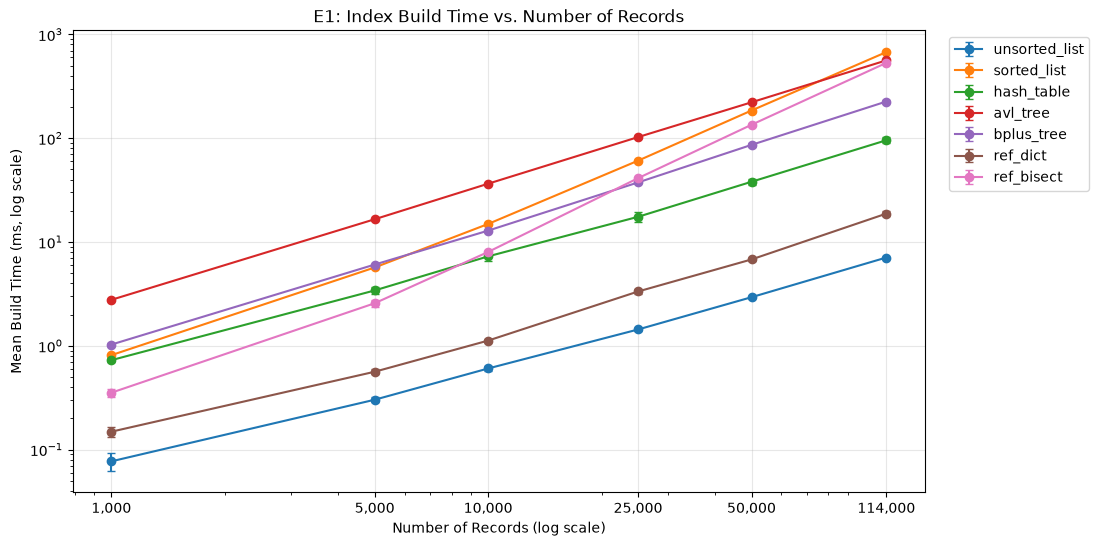

In [4]:
# Create directory for saving E1 charts
fig_dir = project_root / 'analysis' / 'figures_E1'
fig_dir.mkdir(parents=True, exist_ok=True)

# Seven types of indexes
index_types = [
    'unsorted_list',
    'sorted_list',
    'hash_table',
    'avl_tree',
    'bplus_tree',
    'ref_dict',
    'ref_bisect',
]

# create plt
fig, ax = plt.subplots(figsize=(11, 6))

# Plot the average construction time and standard deviation for each type of index separately
for index_type in index_types:
    data = e1_summary.loc[
        e1_summary['index_type'] == index_type
    ].sort_values('n_keys')

    ax.errorbar(
        data['n_keys'],
        data['mean_build_ms'],
        yerr=data['std_build_ms'],
        marker='o',
        capsize=3,
        label=index_type,
    )

# Using logarithmic coordinates makes it convenient to compare the construction times of different magnitudes.
ax.set_xscale('log')
ax.set_yscale('log')

# Set the labels and titles of the coordinate axes
ax.set_xlabel('Number of Records (log scale)')
ax.set_ylabel('Mean Build Time (ms, log scale)')
ax.set_title('E1: Index Build Time vs. Number of Records')

# Display six actual test scales
sizes = sorted(e1_summary['n_keys'].unique())
ax.set_xticks(sizes)
ax.set_xticklabels([f'{int(n):,}' for n in sizes])

# Add grids and legends
ax.grid(True, which='major', alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))

# save plt
fig_path = fig_dir / 'E1_build_time.png'
fig.savefig(fig_path, dpi=300, bbox_inches='tight')

print(f'Saved location：{fig_path}')
plt.show()


Saved location：/project/analysis/figures_E1/E1_memory_usage.png


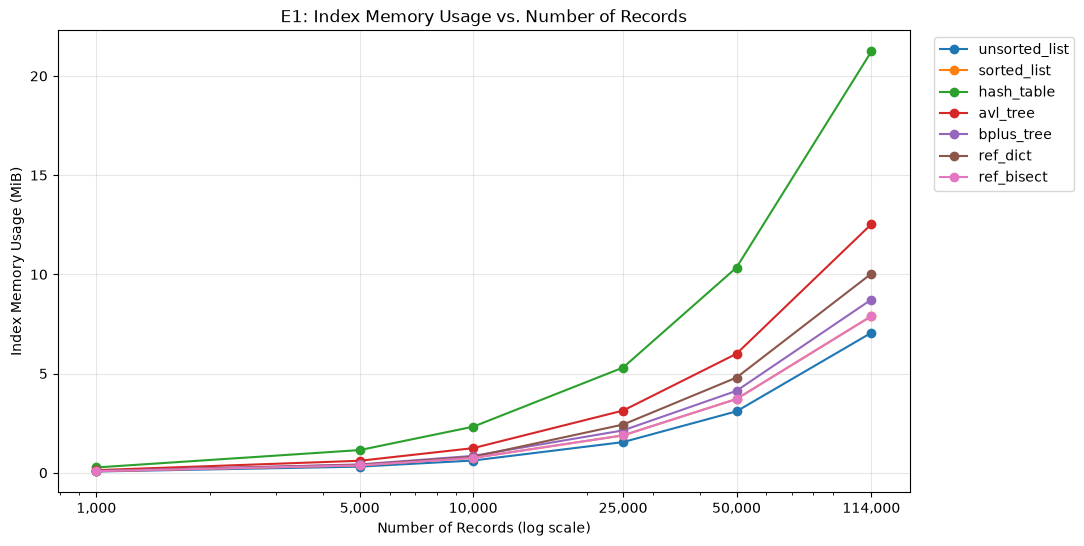

In [5]:
# Draw a comparison chart of the index memory usage for E1
fig_mem, ax_mem = plt.subplots(figsize=(11, 6))

# Draw the memory usage of each of the seven indexes separately
for index_type in index_types:
    data = e1_summary.loc[
        e1_summary['index_type'] == index_type
    ].sort_values('n_keys')

    ax_mem.plot(
        data['n_keys'],
        data['memory_mib'],
        marker='o',
        label=index_type,
    )

# The horizontal axis uses a logarithmic scale to facilitate the display of six different data magnitudes.
ax_mem.set_xscale('log')

# Set the names of the coordinate axes and the title of the chart
ax_mem.set_xlabel('Number of Records (log scale)')
ax_mem.set_ylabel('Index Memory Usage (MiB)')
ax_mem.set_title('E1: Index Memory Usage vs. Number of Records')

# Indicate the actual test scale
ax_mem.set_xticks(sizes)
ax_mem.set_xticklabels([f'{int(n):,}' for n in sizes])

# Add grid and legend
ax_mem.grid(True, which='major', alpha=0.3)
ax_mem.legend(loc='upper left', bbox_to_anchor=(1.02, 1))

# Save plt
memory_fig_path = fig_dir / 'E1_memory_usage.png'
fig_mem.savefig(memory_fig_path, dpi=300, bbox_inches='tight')

print(f'Saved location：{memory_fig_path}')
plt.show()


In [6]:
# Select the result under the smallest data scale
small = e1_summary.loc[
    e1_summary['n_keys'] == 1_000,
    ['index_type', 'mean_build_ms']
].rename(columns={
    'mean_build_ms': 'build_1000_ms'
})

# Select the result under the maximum data size
large = e1_summary.loc[
    e1_summary['n_keys'] == 114_000,
    ['index_type', 'mean_build_ms', 'memory_mib']
].rename(columns={
    'mean_build_ms': 'build_114000_ms',
    'memory_mib': 'memory_114000_mib'
})

# Merge the results of the two scales based on the index type
e1_comparison = small.merge(
    large,
    on='index_type',
    validate='one_to_one'
)

# Calculate the growth factor of the construction time
e1_comparison['build_growth_x'] = (
    e1_comparison['build_114000_ms']
    / e1_comparison['build_1000_ms']
)

# Sort by the construction time in descending order from the largest scale.
e1_comparison = e1_comparison.sort_values(
    'build_114000_ms'
).reset_index(drop=True)

# Display the final comparison table
display(e1_comparison.round(3))


,index_type,build_1000_ms,build_114000_ms,memory_114000_mib,build_growth_x
0,unsorted_list,0.077,7.086,7.055,92.019
1,ref_dict,0.149,18.770,10.033,126.303
2,hash_table,0.727,95.584,21.233,131.519
3,bplus_tree,1.027,225.769,8.730,219.790
4,ref_bisect,0.353,532.444,7.894,1508.382
5,avl_tree,2.771,562.600,12.529,203.004
6,sorted_list,0.812,675.922,7.894,832.294


In [7]:
# Calculate the median and quartiles of the five repeated measurements for each configuration.
e1_distribution = (
    e1.groupby(['n_keys', 'index_type'], as_index=False)
    .agg(
        reps=('build_ms', 'size'),
        median_ms=('build_ms', 'median'),
        q1_ms=('build_ms', lambda x: x.quantile(0.25)),
        q3_ms=('build_ms', lambda x: x.quantile(0.75)),
    )
)

# Interquartile range: The third quartile minus the first quartile
e1_distribution['iqr_ms'] = (
    e1_distribution['q3_ms'] - e1_distribution['q1_ms']
)

# Check if all 42 configurations have undergone five measurements
assert len(e1_distribution) == 42
assert e1_distribution['reps'].eq(5).all()

# Fit the log-log slope using the average build times of six scales
growth_records = []

for index_type, group in e1_summary.groupby('index_type'):
    group = group.sort_values('n_keys')

    x = np.log10(group['n_keys'].to_numpy(dtype=float))
    y = np.log10(group['mean_build_ms'].to_numpy(dtype=float))

    # Fit log(time) = slope * log(n) + intercept
    slope, intercept = np.polyfit(x, y, 1)

    growth_records.append({
        'index_type': index_type,
        'log_log_slope': slope,
    })

e1_growth = (
    pd.DataFrame(growth_records)
    .sort_values('log_log_slope')
    .reset_index(drop=True)
)

# Display the median and interquartile range at the maximum scale
print('Median and IQR at n = 114,000:')
display(
    e1_distribution.loc[
        e1_distribution['n_keys'] == 114_000
    ].round(3)
)

# Display the growth rates of all seven types of indexes
print('Log-log slope for all seven indexes:')
display(e1_growth.round(3))


Median and IQR at n = 114,000:


,n_keys,index_type,reps,median_ms,q1_ms,q3_ms,iqr_ms
35,114000,avl_tree,5,560.291,558.947,564.566,5.619
36,114000,bplus_tree,5,224.366,223.725,224.368,0.643
37,114000,hash_table,5,93.650,90.161,98.146,7.985
38,114000,ref_bisect,5,530.325,529.951,531.365,1.415
39,114000,ref_dict,5,18.811,18.275,19.658,1.383
40,114000,sorted_list,5,680.726,671.167,681.235,10.068
41,114000,unsorted_list,5,7.065,7.058,7.066,0.008


Log-log slope for all seven indexes:


,index_type,log_log_slope
0,unsorted_list,0.956
1,hash_table,1.028
2,ref_dict,1.028
3,avl_tree,1.123
4,bplus_tree,1.140
5,sorted_list,1.430
6,ref_bisect,1.573


Saved location: /project/analysis/figures_E1/E1_build_time_median_iqr.png


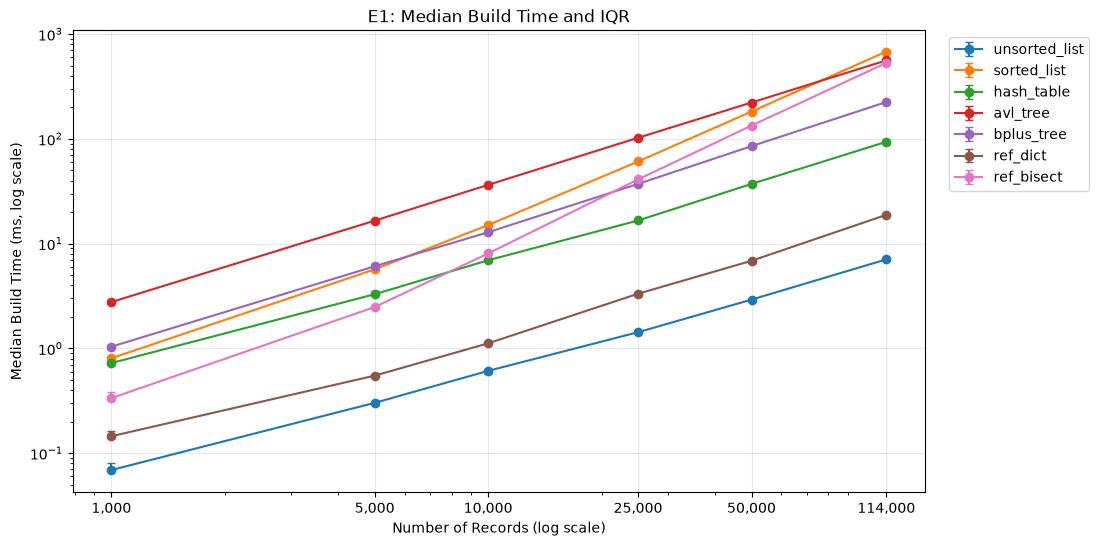

In [8]:
# Draw the Median + IQR construction time chart
fig_median, ax_median = plt.subplots(figsize=(11, 6))

for index_type in index_types:
    data = e1_distribution.loc[
        e1_distribution['index_type'] == index_type
    ].sort_values('n_keys')

    # Calculate the quartile distance on both sides of the median.
    lower_error = data['median_ms'] - data['q1_ms']
    upper_error = data['q3_ms'] - data['median_ms']

    ax_median.errorbar(
        data['n_keys'],
        data['median_ms'],
        yerr=[lower_error, upper_error],
        marker='o',
        capsize=3,
        label=index_type,
    )

# Use logarithmic scale
ax_median.set_xscale('log')
ax_median.set_yscale('log')

# Set the title and axis labels
ax_median.set_title('E1: Median Build Time and IQR')
ax_median.set_xlabel('Number of Records (log scale)')
ax_median.set_ylabel('Median Build Time (ms, log scale)')

ax_median.set_xticks(sizes)
ax_median.set_xticklabels([f'{int(n):,}' for n in sizes])

ax_median.grid(True, which='major', alpha=0.3)
ax_median.legend(loc='upper left', bbox_to_anchor=(1.02, 1))

# save plt
median_fig_path = fig_dir / 'E1_build_time_median_iqr.png'
fig_median.savefig(median_fig_path, dpi=300, bbox_inches='tight')

print(f'Saved location: {median_fig_path}')
plt.show()
